In [4]:
from dotenv import load_dotenv
from datasets import Dataset, load_dataset
import matplotlib.pyplot as plt
import os
os.environ["CLOUDSDK_ACTIVE_CONFIG_NAME"] = "capstone-env"

from utils.bq import get_client, query_to_df
from utils.load_yaml_helper import get_sql_dir, load_yaml, get_artifacts_dir
from utils.logging_helper import setup_logging
from data_pipelines.preprocessing_scripts.triage_vitals_preprocessing import (
    clean_vital_sign_outliers,
    clean_pain_column,
    remap_stay_ids,
    filter_to_cohort,
    fill_triage_charttimes,
    drop_pre_admission_rows,
    drop_same_time_vitals,
)
from data_pipelines.feature_engineering.triage_vitals_features import (
    add_time_since_last,
    forward_fill_and_flag_missing,
    add_vital_features,
)

import pandas as pd
from scipy.stats import chi2_contingency
import numpy as np

In [5]:
settings = load_yaml("project_setup/settings.yaml")
SQL_DIR = get_sql_dir()

client, PROJECT_NAME = get_client()

triage_query = (SQL_DIR / "triage.sql").read_text().format(PROJECT_NAME=PROJECT_NAME)
vitals_query = (SQL_DIR / "vitals.sql").read_text().format(PROJECT_NAME=PROJECT_NAME)
df_triage = query_to_df(client, triage_query)

In [6]:
cols = [c for c in df_triage.columns[2:8]]

In [7]:
for c in cols:
    df_triage[c] = pd.to_numeric(df_triage[c], errors='coerce')

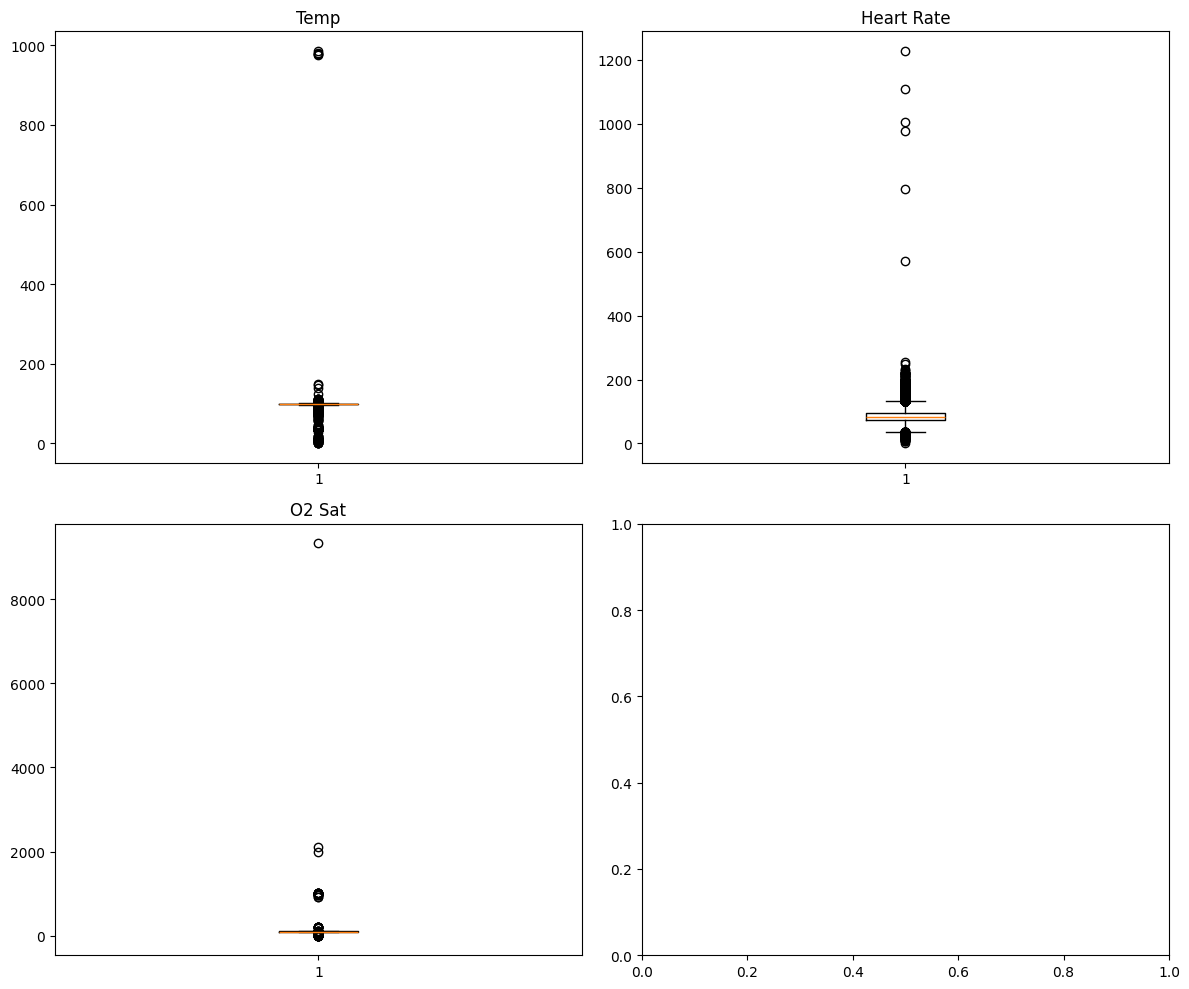

In [8]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 2, figsize= (12, 10))
ax = axs.flatten()

ax[0].boxplot(df_triage['temperature'].dropna())
ax[1].boxplot(df_triage['heartrate'].dropna())
ax[2].boxplot(df_triage['o2sat'].dropna())

ax[0].set_title("Temp")
ax[1].set_title("Heart Rate")
ax[2].set_title("O2 Sat")

plt.tight_layout()
plt.show()

# Patient Distribution

In [9]:
pd.set_option('display.max_columns', 300)

ds = load_dataset("ADS599-Capstone/modeling_data", name="full_patient_state", split="full_patient_state", verification_mode="no_checks")
df = ds.to_pandas()

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/27 [00:00<?, ?it/s]

In [10]:
df.head()

,ed_stay_id,time,step_idx,subject_id,hadm_id,stay_window_start,stay_window_end,gender,anchor_age,admission_type,cohort_label,terminal_event,acuity,current_temperature,current_heartrate,current_resprate,current_o2sat,current_sbp,current_dbp,current_pain,chiefcomplaint,time_since_last_min,pain_missing,heartrate_missing,o2sat_missing,acuity_missing,resprate_missing,sbp_missing,dbp_missing,temperature_missing,temperature_delta,heartrate_delta,resprate_delta,o2sat_delta,sbp_delta,dbp_delta,pain_delta,temperature_rate_per_min,heartrate_rate_per_min,resprate_rate_per_min,o2sat_rate_per_min,sbp_rate_per_min,dbp_rate_per_min,current_mean_arterial_pressure,temperature_rolling1h,heartrate_rolling1h,resprate_rolling1h,o2sat_rolling1h,sbp_rolling1h,dbp_rolling1h,vitals_checked,Blood Gas-Blood_Pending,Blood Gas-Blood_Normal,Blood Gas-Blood_Abnormal,Blood Gas-Other Body Fluid_Pending,Blood Gas-Other Body Fluid_Normal,Blood Gas-Other Body Fluid_Abnormal,Chemistry-Ascites_Pending,Chemistry-Ascites_Normal,Chemistry-Ascites_Abnormal,Chemistry-Blood_Pending,Chemistry-Blood_Normal,Chemistry-Blood_Abnormal,Chemistry-Cerebrospinal Fluid_Pending,Chemistry-Cerebrospinal Fluid_Normal,Chemistry-Cerebrospinal Fluid_Abnormal,Chemistry-Joint Fluid_Pending,Chemistry-Joint Fluid_Normal,Chemistry-Joint Fluid_Abnormal,Chemistry-Other Body Fluid_Pending,Chemistry-Other Body Fluid_Normal,Chemistry-Other Body Fluid_Abnormal,Chemistry-Pleural_Pending,Chemistry-Pleural_Normal,Chemistry-Pleural_Abnormal,Chemistry-Stool_Pending,Chemistry-Stool_Normal,Chemistry-Stool_Abnormal,Chemistry-Urine_Pending,Chemistry-Urine_Normal,Chemistry-Urine_Abnormal,Hematology-Ascites_Pending,Hematology-Ascites_Normal,Hematology-Ascites_Abnormal,Hematology-Blood_Pending,Hematology-Blood_Normal,Hematology-Blood_Abnormal,Hematology-Bone Marrow_Pending,Hematology-Bone Marrow_Normal,Hematology-Bone Marrow_Abnormal,Hematology-Cerebrospinal Fluid_Pending,Hematology-Cerebrospinal Fluid_Normal,Hematology-Cerebrospinal Fluid_Abnormal,Hematology-Joint Fluid_Pending,Hematology-Joint Fluid_Normal,Hematology-Joint Fluid_Abnormal,Hematology-Other Body Fluid_Pending,Hematology-Other Body Fluid_Normal,Hematology-Other Body Fluid_Abnormal,Hematology-Pleural_Pending,Hematology-Pleural_Normal,Hematology-Pleural_Abnormal,Hematology-Stool_Pending,Hematology-Stool_Normal,Hematology-Stool_Abnormal,Hematology-Urine_Pending,Hematology-Urine_Normal,Hematology-Urine_Abnormal,labs_ordered,ABSCESS_Pending,ABSCESS_Negative,ABSCESS_Positive,ABSCESS_Other,BILE_Pending,BILE_Negative,BILE_Positive,BILE_Other,BLOOD CULTURE_Pending,BLOOD CULTURE_Negative,BLOOD CULTURE_Positive,BLOOD CULTURE_Other,BRONCHOALVEOLAR LAVAGE_Pending,BRONCHOALVEOLAR LAVAGE_Negative,BRONCHOALVEOLAR LAVAGE_Positive,BRONCHOALVEOLAR LAVAGE_Other,Blood (CMV AB)_Pending,Blood (CMV AB)_Negative,Blood (CMV AB)_Positive,Blood (CMV AB)_Other,Blood (EBV)_Pending,Blood (EBV)_Negative,Blood (EBV)_Positive,Blood (EBV)_Other,CSF;SPINAL FLUID_Pending,CSF;SPINAL FLUID_Negative,CSF;SPINAL FLUID_Positive,CSF;SPINAL FLUID_Other,"FLUID,OTHER_Pending","FLUID,OTHER_Negative","FLUID,OTHER_Positive","FLUID,OTHER_Other",IMMUNOLOGY_Pending,IMMUNOLOGY_Negative,IMMUNOLOGY_Positive,IMMUNOLOGY_Other,JOINT FLUID_Pending,JOINT FLUID_Negative,JOINT FLUID_Positive,JOINT FLUID_Other,MRSA SCREEN_Pending,MRSA SCREEN_Negative,MRSA SCREEN_Positive,MRSA SCREEN_Other,OTHER_Pending,OTHER_Negative,OTHER_Positive,OTHER_Other,PERITONEAL FLUID_Pending,PERITONEAL FLUID_Negative,PERITONEAL FLUID_Positive,PERITONEAL FLUID_Other,PLEURAL FLUID_Pending,PLEURAL FLUID_Negative,PLEURAL FLUID_Positive,PLEURAL FLUID_Other,Rapid Respiratory Viral Screen & Culture_Pending,Rapid Respiratory Viral Screen & Culture_Negative,Rapid Respiratory Viral Screen & Culture_Positive,Rapid Respiratory Viral Screen & Culture_Other,SEROLOGY/BLOOD_Pending,SEROLOGY/BLOOD_Negative,SEROLOGY/BLOOD_Positive,SEROLOGY/BLOOD_Other,SPUTUM_Pending,SPUTUM_Negative,SPUTUM_Positive,SPUTUM_Other,STOOL_Pending,STOOL_Negative,STOOL_Posit

In [11]:
df.groupby("terminal_event")['ed_stay_id'].nunique() / df['ed_stay_id'].nunique()

terminal_event
discharge       0.922038
transfer_icu    0.077962
Name: ed_stay_id, dtype: float64

In [12]:
df['ed_stay_id'].nunique()

397669

In [13]:
start = df.iloc[0, 5]
end = df.iloc[0, 6]

In [14]:
delta = end-start

In [15]:
delta.total_seconds() / 86_400

2.870138888888889

In [16]:
397_669 / 196_405

2.0247396960362516

In [17]:
number_of_visits = df.groupby('subject_id')['ed_stay_id'].nunique()
number_of_visits.sort_values(ascending=False)

subject_id
15496609    270
10577647    154
14394983    153
16233333    146
14508231    109
           ... 
19999175      1
19999156      1
19999145      1
19999068      1
19999018      1
Name: ed_stay_id, Length: 196405, dtype: int64

In [18]:
total_one = (number_of_visits.values == 1).sum()

print(total_one)

total_one / number_of_visits.shape[0]

130360


np.float64(0.66373055675772)

unique_subjects = 196,405

max_number = 270

min = 1

In [19]:
granular_bins = pd.cut(number_of_visits, [1, 2, 5, 10, 50, max(number_of_visits) + 1], include_lowest=True, right=False, labels=['1', '2-4', '5-9', '10-49', '50+'])
granular_counts = granular_bins.value_counts(sort=False)

In [20]:
mask = number_of_visits.between(2, 4)

number_of_visits[mask].sum()

np.int64(129080)

In [21]:
granular_counts

ed_stay_id
1        130360
2-4       51071
5-9       10897
10-49      3988
50+          89
Name: count, dtype: int64

In [22]:
granular_counts / number_of_visits.shape

ed_stay_id
1        0.663731
2-4      0.260029
5-9      0.055482
10-49    0.020305
50+      0.000453
Name: count, dtype: float64

<Axes: xlabel='ed_stay_id'>

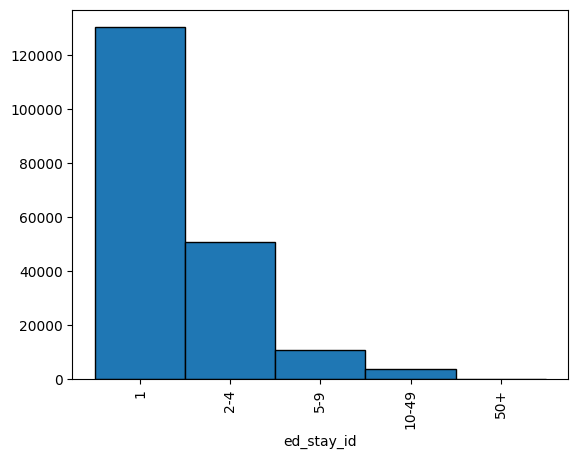

In [23]:
granular_counts.plot(kind='bar', width=1.0, edgecolor='black')

# Demographics

In [24]:
cohort_ds = load_dataset("ADS599-Capstone/interim_data", name="cohort_full", split="cohort_base", verification_mode="no_checks")
cohort_df = cohort_ds.to_pandas()

<Axes: xlabel='race'>

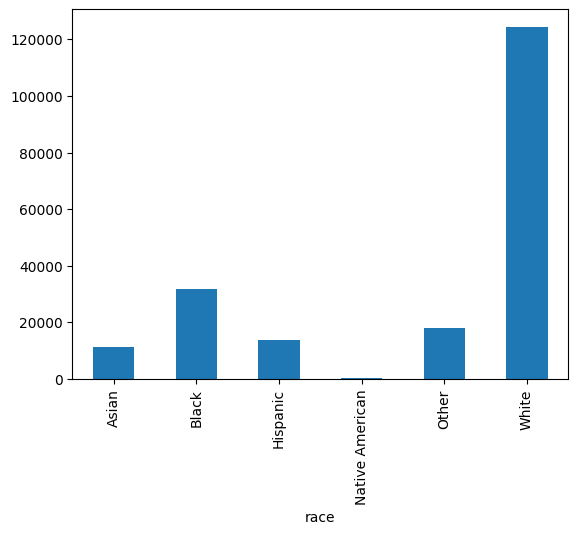

In [25]:
counts = cohort_df.groupby('race')['subject_id'].nunique()
counts.plot(kind='bar')

<Axes: xlabel='race,language'>

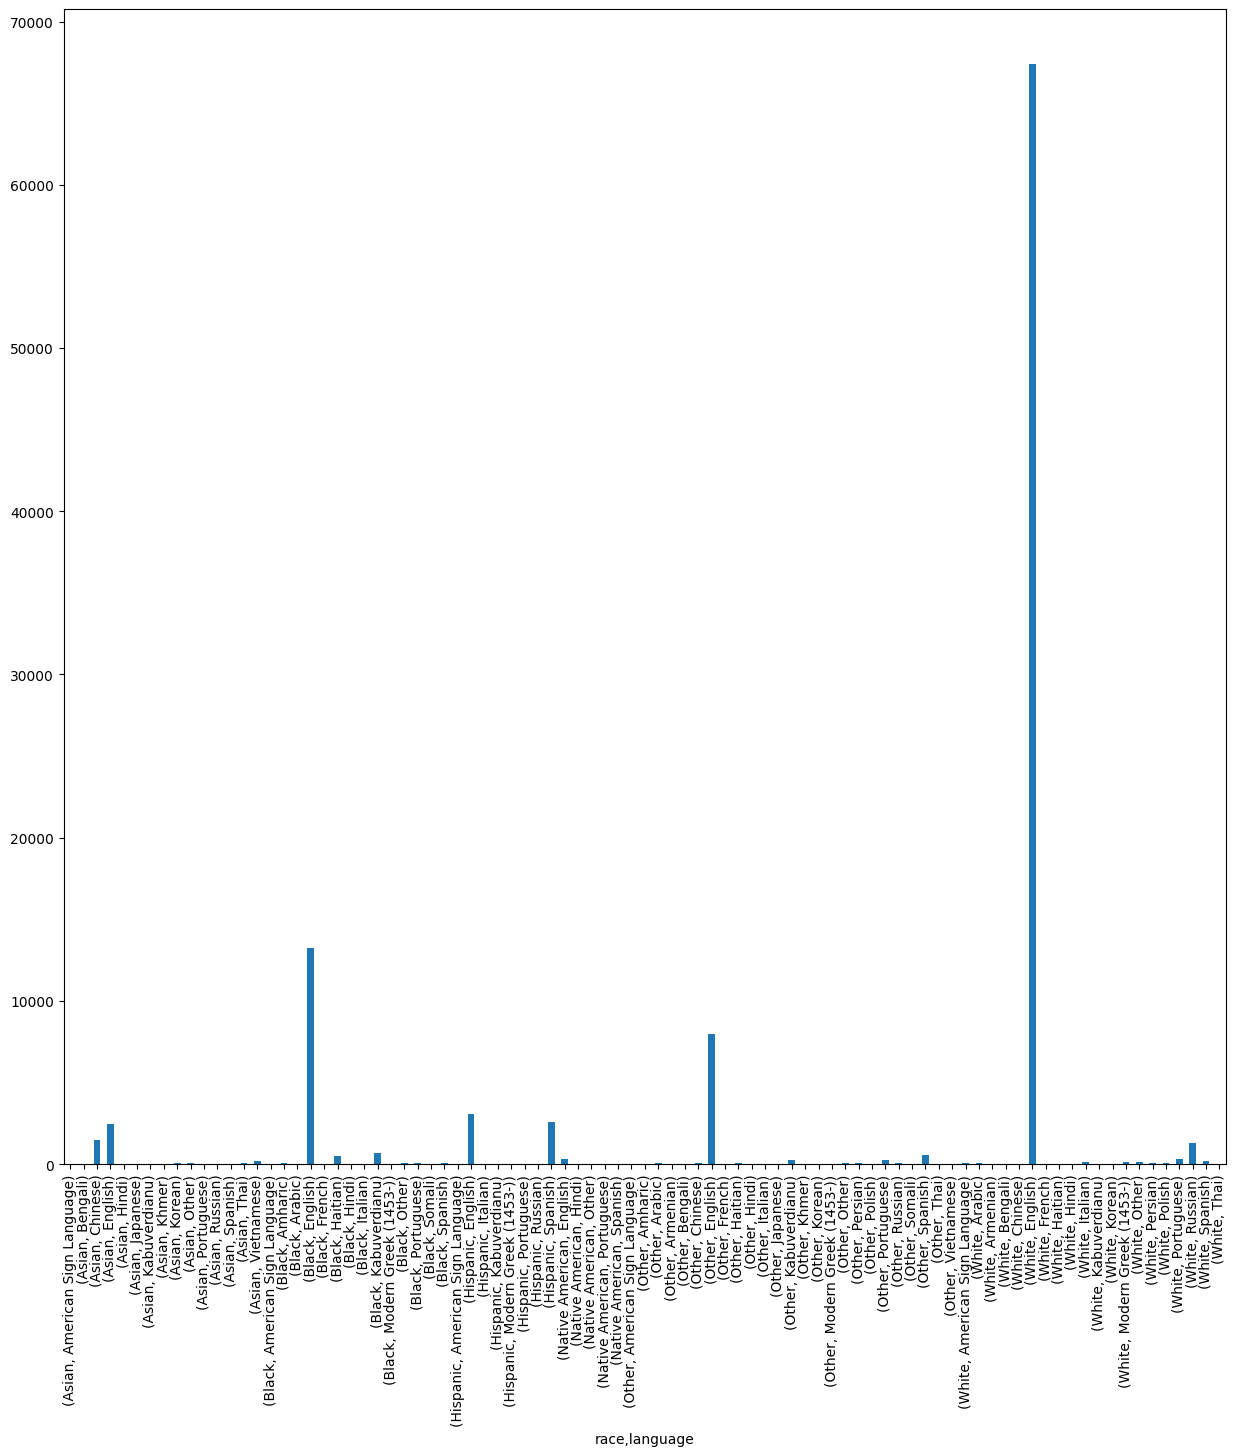

In [26]:
fig = plt.figure(figsize=(15, 15))

counts = cohort_df.groupby(['race', 'language'])['subject_id'].nunique()
counts.plot(kind='bar')

<Axes: xlabel='language'>

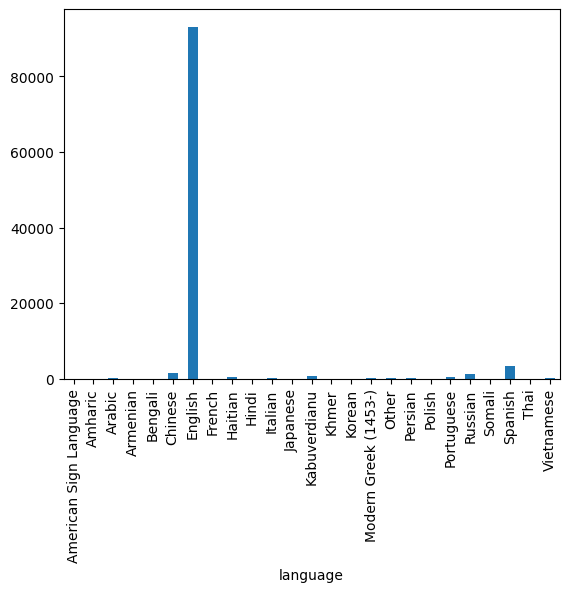

In [27]:
counts = cohort_df.groupby('language')['subject_id'].nunique()
counts.plot(kind='bar')

<Axes: xlabel='gender'>

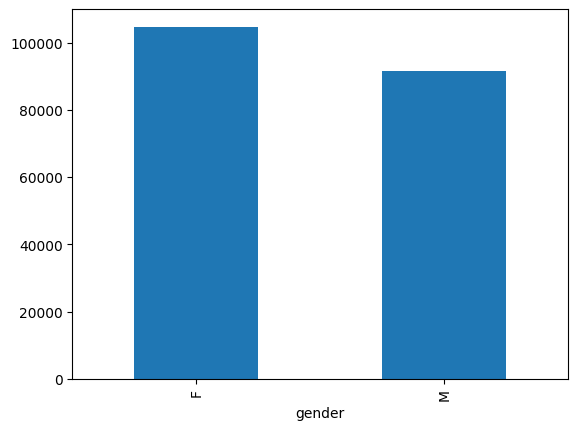

In [28]:
counts = cohort_df.groupby('gender')['subject_id'].nunique()
counts.plot(kind='bar')

<Axes: xlabel='insurance'>

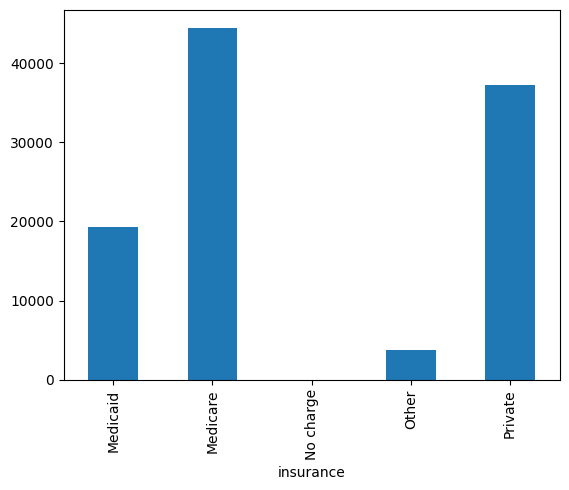

In [29]:
counts = cohort_df.groupby('insurance')['subject_id'].nunique()
counts.plot(kind='bar')

<Axes: xlabel='marital_status'>

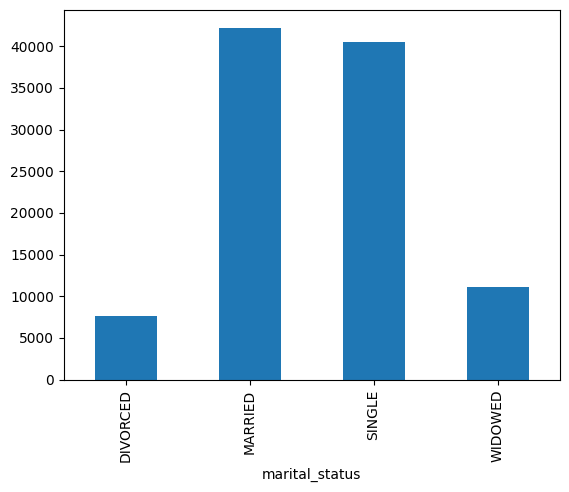

In [30]:
counts = cohort_df.groupby('marital_status')['subject_id'].nunique()
counts.plot(kind='bar')

# Feature-Outcome Relationships

**Goal:** screen every candidate feature against the binary outcome (`label`: 0 = discharge, 1 = ICU transfer) to see which relationships stand out before writing up the Data Understanding section.

**Design choices**
- **Unit of analysis = one ED stay.** `full_patient_state` has one row per event, and ICU stays have about 3x more rows than discharges, so row-level means overweight long stays. Each stay is collapsed with `load_and_prep()` from `modeling/data_prep/traditional_ml.py`: triage vitals (first value) plus the max of each binary clinical flag over the **first 60 minutes**. This matches the baseline model inputs and keeps information that arrives later in the stay (and is closer to the outcome) out of the analysis.
- **One visit per patient for inferential tests.** About 1/3 of patients have repeat visits, which violates the independence assumption behind chi-squared, t-tests and Mann-Whitney U. Tests run on one randomly sampled stay per `subject_id`; descriptive plots use all stays.
- **Effect sizes over p-values.** With ~196k independent stays nearly every test is significant, so the ranking is driven by effect size (rank-biserial r, Cramér's V). p-values are Benjamini-Hochberg adjusted within each test family.
- **Imputed values excluded from continuous tests.** Vitals were mean-imputed and height/weight were zero-filled upstream. Those values are masked back to NaN using the `*_missing` flags so the imputation spikes don't distort the distributions.

| Feature type | Visual | Test | Effect size |
|---|---|---|---|
| Continuous / ordinal | Boxplot + KDE overlay | Welch t-test, Mann-Whitney U | Point-biserial r, rank-biserial r, Cohen's d |
| Categorical (multi-level) | ICU rate per level | Chi-squared | Cramér's V |
| Binary clinical flags | Prevalence dumbbell | Chi-squared (2x2) | Cramér's V (= abs(phi)), risk ratio |
| All (multivariate) | Ranked bar | Mutual information, RF permutation importance | - |

## Setup

In [31]:
import gc

from scipy.stats import (
    chi2_contingency,
    false_discovery_control,
    gaussian_kde,
    mannwhitneyu,
    pointbiserialr,
    ttest_ind,
)
from scipy.stats.contingency import association
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score
from sklearn.model_selection import train_test_split

from modeling.data_prep.columns import get_column_groups
from modeling.data_prep.traditional_ml import load_and_prep, _map_cc

RANDOM_STATE = 10
TARGET = 'label'
OUTCOME_NAMES = {0: 'Discharge', 1: 'ICU transfer'}
OUTCOME_COLORS = {0: '#2a78d6', 1: '#eb6834'}
INK = '#52514e'
GRID = '#e4e3df'

plt.rcParams.update({
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': GRID,
    'axes.labelcolor': INK,
    'xtick.color': INK,
    'ytick.color': INK,
    'axes.titlesize': 11,
    'axes.titleweight': 'bold',
    'axes.grid': True,
    'grid.color': GRID,
    'grid.linewidth': 0.6,
})

In [32]:
def effect_magnitude(value, dof=1):
    """Cohen's conventions. For Cramer's V the cutoffs shrink as min(rows, cols) - 1 grows."""
    v = abs(value)
    cutoffs = {1: (0.1, 0.3, 0.5), 2: (0.07, 0.21, 0.35)}.get(dof, (0.06, 0.17, 0.29))
    if v < cutoffs[0]:
        return 'negligible'
    if v < cutoffs[1]:
        return 'small'
    if v < cutoffs[2]:
        return 'medium'
    return 'large'


def mask_imputed(data, col):
    """Return col with imputed values set to NaN, using the matching *_missing flag if one exists."""
    base = col.removeprefix('current_')
    for flag in (f'{base}_missing', f'{col}_missing'):
        if flag in data.columns:
            return data[col].where(data[flag] == 0)
    return data[col]


def continuous_tests(data, features, target=TARGET):
    rows = []
    for col in features:
        sub = pd.DataFrame({'x': mask_imputed(data, col), 'y': data[target]}).dropna()
        icu = sub.loc[sub['y'] == 1, 'x']
        dis = sub.loc[sub['y'] == 0, 'x']
        if sub['x'].nunique() < 2:
            continue

        _, t_p = ttest_ind(icu, dis, equal_var=False)
        u_stat, u_p = mannwhitneyu(icu, dis, alternative='two-sided')
        r_pb, _ = pointbiserialr(sub['y'], sub['x'])
        # Positive rank-biserial = ICU values tend to be higher
        r_rb = 2 * u_stat / (len(icu) * len(dis)) - 1
        pooled_sd = np.sqrt(((len(icu) - 1) * icu.var() + (len(dis) - 1) * dis.var()) / (len(sub) - 2))

        rows.append({
            'feature': col,
            'n': len(sub),
            'pct_excluded': 1 - len(sub) / len(data),
            'mean_discharge': dis.mean(),
            'mean_icu': icu.mean(),
            'median_discharge': dis.median(),
            'median_icu': icu.median(),
            'welch_t_p': t_p,
            'mwu_p': u_p,
            'point_biserial_r': r_pb,
            'rank_biserial_r': r_rb,
            'cohens_d': (icu.mean() - dis.mean()) / pooled_sd,
        })

    out = pd.DataFrame(rows)
    out['welch_t_p_adj'] = false_discovery_control(out['welch_t_p'])
    out['mwu_p_adj'] = false_discovery_control(out['mwu_p'])
    out['effect'] = out['rank_biserial_r'].apply(effect_magnitude)
    return out.sort_values('rank_biserial_r', key=abs, ascending=False).reset_index(drop=True)


def categorical_tests(data, features, target=TARGET):
    rows = []
    for col in features:
        table = pd.crosstab(data[col], data[target])
        if table.shape[0] < 2 or table.shape[1] < 2:
            continue
        chi2, p, dof, expected = chi2_contingency(table)
        icu_rate = table[1] / table.sum(axis=1)
        v = association(table, method='cramer')
        rows.append({
            'feature': col,
            'levels': table.shape[0],
            'chi2': chi2,
            'dof': dof,
            'p': p,
            'cramers_v': v,
            'pct_cells_expected_lt5': (expected < 5).mean(),
            'highest_icu_level': icu_rate.idxmax(),
            'highest_icu_rate': icu_rate.max(),
            'lowest_icu_level': icu_rate.idxmin(),
            'lowest_icu_rate': icu_rate.min(),
            'effect': effect_magnitude(v, min(table.shape) - 1),
        })

    out = pd.DataFrame(rows)
    out['p_adj'] = false_discovery_control(out['p'])
    return out.sort_values('cramers_v', ascending=False).reset_index(drop=True)


def binary_flag_tests(data, flags, target=TARGET):
    """2x2 chi-squared per flag plus prevalence in each outcome group and the risk ratio."""
    rows = []
    y = data[target]
    for col in flags:
        x = data[col].fillna(0).astype(int)
        if x.nunique() < 2:
            continue
        table = pd.crosstab(x, y)
        chi2, p, _, _ = chi2_contingency(table)
        icu_if_present = y[x == 1].mean()
        icu_if_absent = y[x == 0].mean()
        rows.append({
            'feature': col,
            'prevalence_discharge': x[y == 0].mean(),
            'prevalence_icu': x[y == 1].mean(),
            'icu_rate_if_present': icu_if_present,
            'icu_rate_if_absent': icu_if_absent,
            'risk_ratio': icu_if_present / icu_if_absent if icu_if_absent > 0 else np.nan,
            'chi2': chi2,
            'p': p,
            'cramers_v': association(table, method='cramer'),
        })

    out = pd.DataFrame(rows)
    out['p_adj'] = false_discovery_control(out['p'])
    out['effect'] = out['cramers_v'].apply(effect_magnitude)
    return out.sort_values('cramers_v', ascending=False).reset_index(drop=True)

In [33]:
def plot_box_grid(data, features, target=TARGET, ncols=4):
    nrows = int(np.ceil(len(features) / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.4 * nrows))
    axs = np.atleast_1d(axs).flatten()
    for ax, col in zip(axs, features):
        values = mask_imputed(data, col)
        groups = [values[data[target] == k].dropna() for k in (0, 1)]
        bp = ax.boxplot(groups, tick_labels=[OUTCOME_NAMES[0], OUTCOME_NAMES[1]], showfliers=False,
                        patch_artist=True, widths=0.5, medianprops={'color': 'white', 'linewidth': 2})
        for patch, k in zip(bp['boxes'], (0, 1)):
            patch.set_facecolor(OUTCOME_COLORS[k])
            patch.set_edgecolor(OUTCOME_COLORS[k])
        ax.set_title(col.removeprefix('current_'))
        ax.grid(axis='x', visible=False)
    for ax in axs[len(features):]:
        ax.set_visible(False)
    fig.suptitle('Distribution by outcome (whiskers 1.5 IQR, outliers hidden)', y=1.0)
    plt.tight_layout()
    plt.show()


def plot_kde_grid(data, features, target=TARGET, ncols=4, max_per_class=20_000):
    """Each class is density-normalized separately, so the 92/8 imbalance doesn't hide the ICU curve."""
    nrows = int(np.ceil(len(features) / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.2 * nrows))
    axs = np.atleast_1d(axs).flatten()
    for ax, col in zip(axs, features):
        values = mask_imputed(data, col)
        lo, hi = values.quantile([0.005, 0.995])
        grid = np.linspace(lo, hi, 300)
        for k in (0, 1):
            x = values[data[target] == k].dropna()
            x = x.sample(min(len(x), max_per_class), random_state=RANDOM_STATE)
            density = gaussian_kde(x)(grid)
            ax.plot(grid, density, color=OUTCOME_COLORS[k], linewidth=2, label=OUTCOME_NAMES[k])
            ax.fill_between(grid, density, color=OUTCOME_COLORS[k], alpha=0.15)
        ax.set_title(col.removeprefix('current_'))
        ax.set_yticks([])
        ax.grid(axis='y', visible=False)
    for ax in axs[len(features):]:
        ax.set_visible(False)
    handles, labels = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.02))
    plt.tight_layout()
    plt.show()


def plot_icu_rate_grid(data, features, target=TARGET, ncols=3, max_levels=25):
    """ICU rate per level with the overall rate as a reference line. Clearer than stacked bars at an 8% base rate."""
    overall = data[target].mean()
    nrows = int(np.ceil(len(features) / ncols))
    heights = [max(3.2, 0.28 * min(data[c].nunique(), max_levels)) for c in features]
    fig, axs = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, max(heights) * nrows))
    axs = np.atleast_1d(axs).flatten()
    for ax, col in zip(axs, features):
        stats = data.groupby(col, observed=True)[target].agg(['mean', 'size'])
        stats = stats.sort_values('mean').tail(max_levels)
        labels = [str(i) for i in stats.index]
        ax.barh(labels, stats['mean'], color=OUTCOME_COLORS[1], height=0.7)
        ax.axvline(overall, color=INK, linestyle='--', linewidth=1)
        for i, (rate, n) in enumerate(zip(stats['mean'], stats['size'])):
            ax.text(rate, i, f' {rate:.1%} (n={n:,})', va='center', fontsize=8, color=INK)
        ax.set_xlim(0, min(1, stats['mean'].max() * 1.45))
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
        ax.set_title(col)
        ax.grid(axis='y', visible=False)
    for ax in axs[len(features):]:
        ax.set_visible(False)
    fig.suptitle(f'ICU transfer rate by level (dashed line = overall {overall:.1%})', y=1.0)
    plt.tight_layout()
    plt.show()


def plot_prevalence_dumbbell(flag_results, top_n=30, title=None):
    top = flag_results.head(top_n).iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 0.32 * len(top) + 1.2))
    y = np.arange(len(top))
    ax.hlines(y, top['prevalence_discharge'], top['prevalence_icu'], color=GRID, linewidth=2)
    for k, col in ((0, 'prevalence_discharge'), (1, 'prevalence_icu')):
        ax.scatter(top[col], y, color=OUTCOME_COLORS[k], s=50, zorder=3, label=OUTCOME_NAMES[k],
                   edgecolor='white', linewidth=1.5)
    ax.set_yticks(y, top['feature'])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    ax.set_xlabel('Share of stays with flag = 1 in the first hour')
    ax.grid(axis='y', visible=False)
    ax.legend(frameon=False, loc='lower right')
    ax.set_title(title or f'Top {top_n} binary flags by Cramer\'s V')
    plt.tight_layout()
    plt.show()


def plot_ranked(series, title, xlabel, top_n=25, color=OUTCOME_COLORS[0]):
    top = series.sort_values().tail(top_n)
    fig, ax = plt.subplots(figsize=(8, 0.3 * len(top) + 1.2))
    ax.barh(top.index, top.values, color=color, height=0.7)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis='y', visible=False)
    plt.tight_layout()
    plt.show()

## Build the stay-level frame

`load_and_prep()` reloads `full_patient_state` from the HF cache. If memory is tight, free the row-level `df` from the earlier sections first (`del df; gc.collect()`).

`use_tfidf=True` keeps the raw `chiefcomplaint` so it can be mapped to a single `cc_category` column for the chi-squared test (rather than 20 separate dummies).

In [35]:
df_stay = load_and_prep(settings['hugging_face'], use_tfidf=True)
df_stay['cc_category'] = df_stay['chiefcomplaint'].apply(_map_cc)
df_stay['current_pain'] = pd.to_numeric(df_stay['current_pain'], errors='coerce')

# Collapse arrival OHE back to one categorical column for the chi-squared test
arrival_cols = [c for c in df_stay.columns if c.startswith('arrival_')]
df_stay['arrival'] = np.where(
    df_stay[arrival_cols].sum(axis=1) > 0,
    df_stay[arrival_cols].idxmax(axis=1).str.removeprefix('arrival_'),
    'Unknown',
)
df_stay['gender_label'] = df_stay['gender'].map({1: 'F', 0: 'M'})

# One random stay per patient for all inferential tests
df_one = df_stay.groupby('subject_id').sample(n=1, random_state=RANDOM_STATE).reset_index(drop=True)

print(f'All stays: {len(df_stay):,} | one per patient: {len(df_one):,}')
print(df_one[TARGET].value_counts(normalize=True).rename(OUTCOME_NAMES))

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/27 [00:00<?, ?it/s]

C:\Users\tkbar\ADS\Capstone\ADS599-Capstone\modeling\data_prep\traditional_ml.py:166: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_stay = df_stay.reset_index().copy()
C:\Users\tkbar\ADS\Capstone\ADS599-Capstone\modeling\data_prep\traditional_ml.py:166: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_stay = df_stay.reset_index().copy()


All stays: 397,669 | one per patient: 196,405
label
Discharge       0.915409
ICU transfer    0.084591
Name: proportion, dtype: float64


In [36]:
# Column groups come from the same naming conventions the models use
groups = get_column_groups(df_stay)

CONTINUOUS = ['anchor_age'] + [c for c in groups.vitals if c != 'current_pain'] + ['height', 'weight']
CONTINUOUS = [c for c in CONTINUOUS if c in df_stay.columns]
ORDINAL = ['acuity', 'current_pain']
CATEGORICAL = ['gender_label', 'race', 'arrival', 'cc_category', 'acuity', 'current_pain']

FLAG_GROUPS = {
    'labs': groups.lab_ohe,
    'micro': groups.micro_ohe,
    'ecg': groups.ecg_ohe,
    'radiology': groups.rad_ohe,
    'dispensed_meds': groups.dispensed_meds,
    'home_meds_recon': groups.recon,
    'missingness': groups.missing,
}
FLAG_GROUPS = {g: [c for c in cols if c in df_stay.columns] for g, cols in FLAG_GROUPS.items()}

print('continuous:', CONTINUOUS)
print({g: len(cols) for g, cols in FLAG_GROUPS.items()})

continuous: ['anchor_age', 'current_temperature', 'current_heartrate', 'current_resprate', 'current_o2sat', 'current_sbp', 'current_dbp', 'current_mean_arterial_pressure', 'height', 'weight']
{'labs': 57, 'micro': 84, 'ecg': 3, 'radiology': 3, 'dispensed_meds': 22, 'home_meds_recon': 19, 'missingness': 10}


## 1. Continuous and ordinal features

- **Welch t-test** compares means; **Mann-Whitney U** compares whole distributions and doesn't assume normality. Vitals are skewed and bounded (O2 sat piles up at 100), so MWU is the primary test and the t-test is reported for completeness.
- **Point-biserial r** is the Pearson correlation with a 0/1 target. It replaces the old correlation heatmap with a coefficient that is valid for a binary outcome.
- **Rank-biserial r** is the MWU effect size: the probability that a random ICU stay has a higher value than a random discharge, minus the reverse. Range -1 to 1, sign = direction. Used to rank features.
- **Cohen's d** gives the mean difference in pooled SD units, for comparison with the clinical literature.
- `pct_excluded` = share of stays dropped because the value was imputed or missing.

In [37]:
cont_results = continuous_tests(df_one, CONTINUOUS + ORDINAL)
cont_results.style.format({
    'n': '{:,}', 'pct_excluded': '{:.1%}',
    'mean_discharge': '{:.2f}', 'mean_icu': '{:.2f}', 'median_discharge': '{:.1f}', 'median_icu': '{:.1f}',
    'welch_t_p': '{:.2e}', 'mwu_p': '{:.2e}', 'welch_t_p_adj': '{:.2e}', 'mwu_p_adj': '{:.2e}',
    'point_biserial_r': '{:.3f}', 'rank_biserial_r': '{:.3f}', 'cohens_d': '{:.3f}',
}).background_gradient(subset=['rank_biserial_r'], cmap='RdBu_r', vmin=-0.5, vmax=0.5)

,feature,n,pct_excluded,mean_discharge,mean_icu,median_discharge,median_icu,welch_t_p,mwu_p,point_biserial_r,rank_biserial_r,cohens_d,welch_t_p_adj,mwu_p_adj,effect
0,acuity,"192,234",2.1%,2.70,1.80,3.0,2.0,0.00e+00,0.00e+00,-0.324,-0.614,-1.305,0.00e+00,0.00e+00,large
1,anchor_age,"196,405",0.0%,47.20,63.22,46.0,65.0,0.00e+00,0.00e+00,0.215,0.437,0.790,0.00e+00,0.00e+00,medium
2,current_o2sat,"184,743",5.9%,98.57,97.09,99.0,98.0,0.00e+00,0.00e+00,-0.184,-0.351,-0.789,0.00e+00,0.00e+00,medium
3,current_pain,"177,639",9.6%,4.03,2.50,4.0,0.0,0.00e+00,0.00e+00,-0.098,-0.247,-0.428,0.00e+00,0.00e+00,small
4,current_resprate,"184,872",5.9%,17.34,18.65,18.0,18.0,7.17e-241,2.66e-272,0.139,0.188,0.589,1.43e-240,5.32e-272,small
5,current_mean_arterial_pressure,"196,405",0.0%,96.72,92.59,95.7,92.3,6.04e-245,2.67e-286,-0.082,-0.169,-0.294,1.45e-244,6.42e-286,small
6,current_dbp,"185,225",5.7%,77.94,73.85,78.0,73.0,3.74e-139,2.73e-187,-0.070,-0.164,-0.291,5.62e-139,4.68e-187,small
7,current_heartrate,"186,369",5.1%,84.27,89.79,83.0,88.0,1.43e-147,9.76e-145,0.075,0.143,0.315,2.45e-147,1.46e-144,small
8,current_sbp,"185,821",5.4%,134.71,130.42,133.0,129.0,1.26e-59,1.34e-94,-0.048,-0.115,-0.200,1.68e-59,1.79e-94,small
9,height,"108,263",44.9%,65.99,67.07,65.7,66.0,3.39e-01,9.00e-06,0.008,0.030,0.031,3.39e-01,1.08e-05,negligible


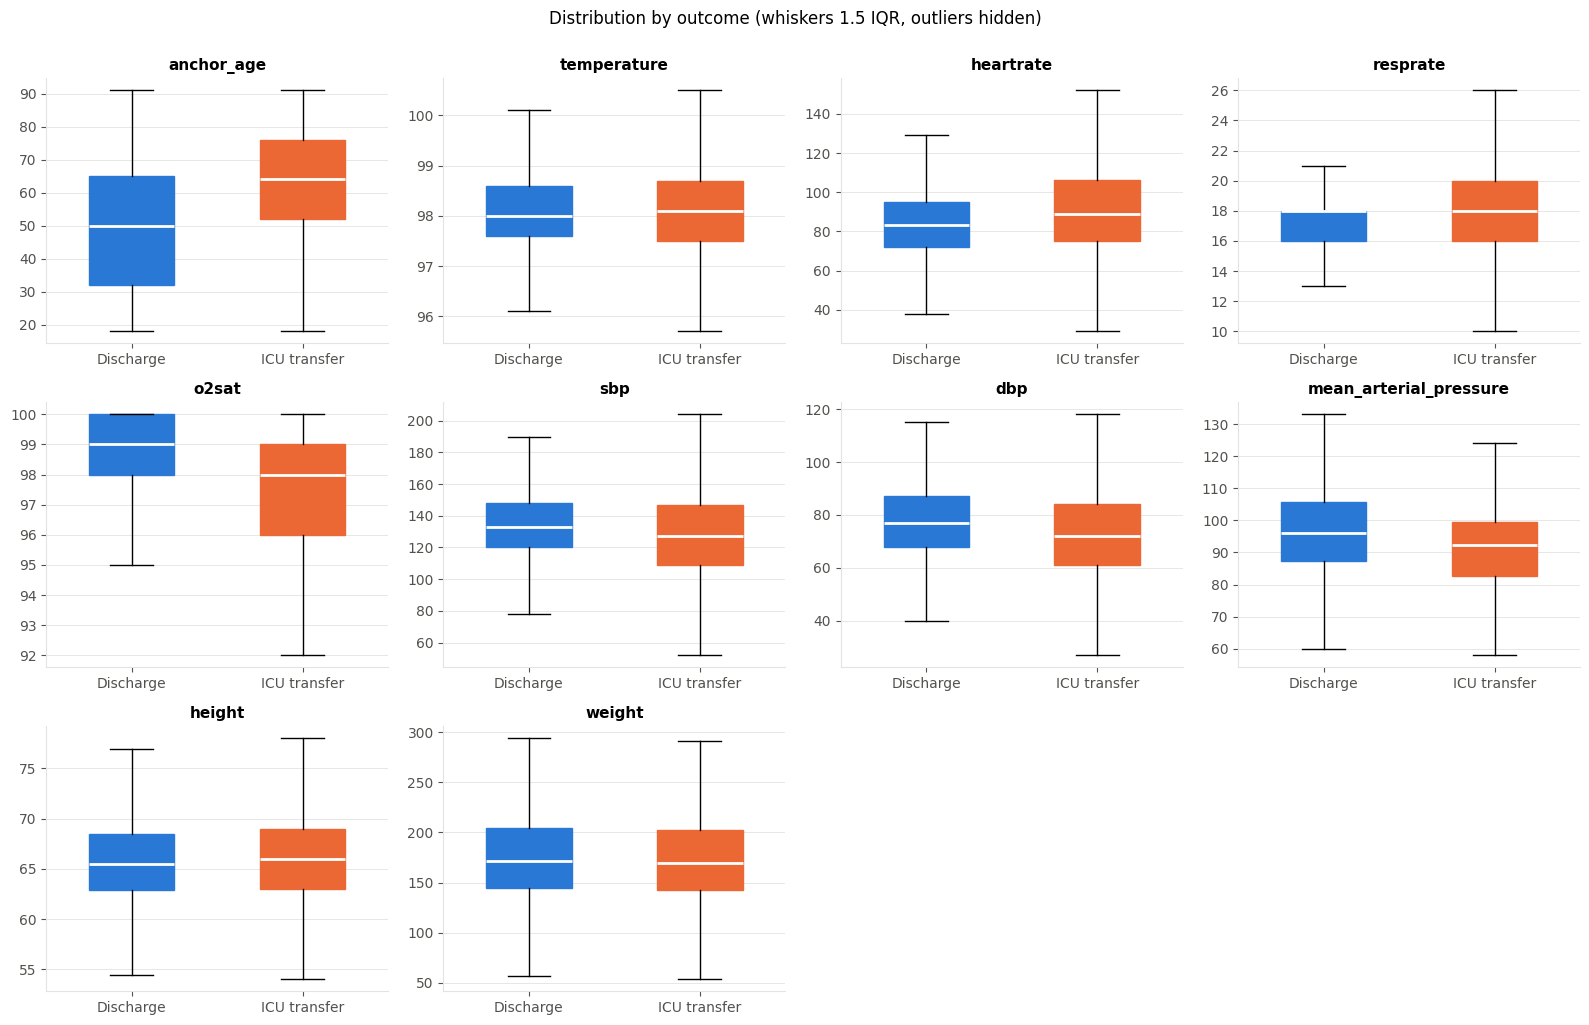

In [38]:
plot_box_grid(df_stay, CONTINUOUS)

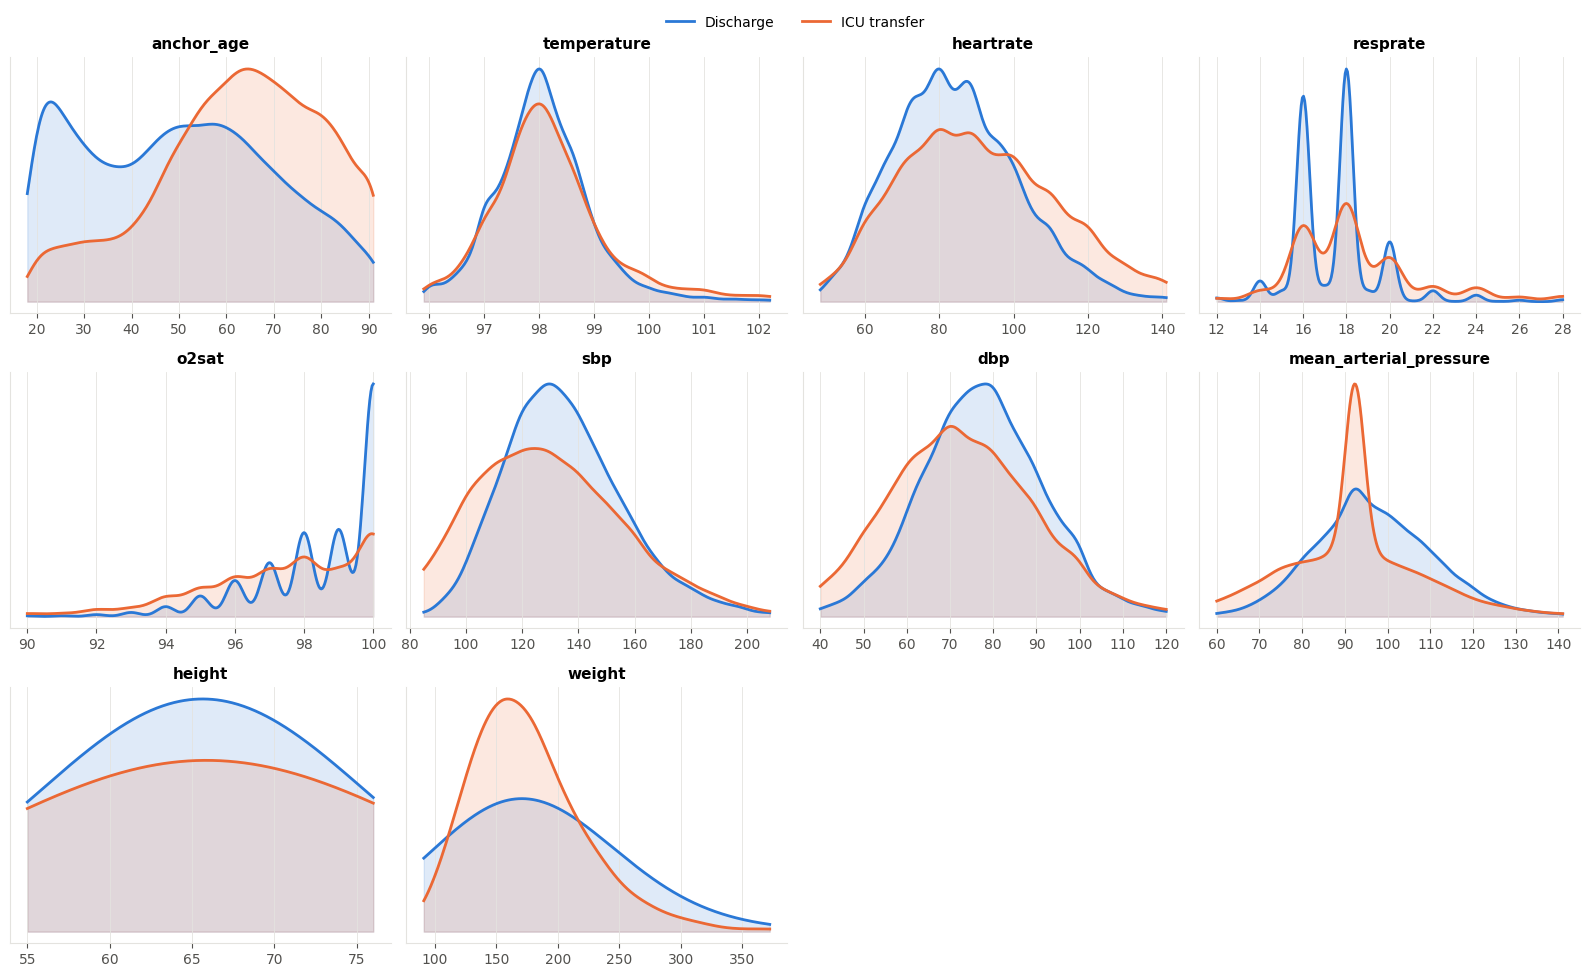

In [39]:
plot_kde_grid(df_stay, CONTINUOUS)

**What to look for:** separation in the KDE peaks (not just tails), whether the ICU curve is wider (more physiologic extremes in both directions, e.g. heart rate and temperature) rather than shifted, which shows up as a small rank-biserial r even when the tails matter clinically, and features where point-biserial and rank-biserial disagree (a sign that outliers drive the linear correlation).

_Observations:_

## 2. Categorical features

### 2a. Multi-level categoricals

**Chi-squared** answers "is the association likely non-random?" At this sample size it almost always is. **Cramér's V** answers "how strong is it?" (0 = none, 1 = perfect). Magnitude labels use Cohen's cutoffs adjusted for table size. `pct_cells_expected_lt5` flags tables where the chi-squared approximation is shaky (sparse levels such as ESI-5 or rare races).

Acuity and pain are ordinal, so they show up here as well as in Section 1.

In [40]:
cat_results = categorical_tests(df_one, CATEGORICAL)
cat_results.style.format({
    'chi2': '{:,.0f}', 'p': '{:.2e}', 'p_adj': '{:.2e}', 'cramers_v': '{:.3f}',
    'pct_cells_expected_lt5': '{:.0%}', 'highest_icu_rate': '{:.1%}', 'lowest_icu_rate': '{:.1%}',
})

KeyError: 'race'

In [ ]:
plot_icu_rate_grid(df_stay, CATEGORICAL)

### 2b. Binary clinical flags (first hour)

Each lab, micro, ECG, radiology, medication and missingness flag is a 2x2 table, so Cramér's V equals abs(phi), which equals the absolute point-biserial r. The **risk ratio** (ICU rate when flag = 1 / ICU rate when flag = 0) is the most interpretable number for the paper ("patients with an abnormal blood gas in the first hour were Nx more likely to go to the ICU").

Many of these flags are a mix of patient state and **clinician behavior**: ordering a blood gas or dispensing a vasopressor reflects the team's own suspicion of deterioration, not just the patient's physiology. Strong associations here partly reflect the provider decision process the RL agent is trying to model.

In [42]:
flag_results = []
for group_name, cols in FLAG_GROUPS.items():
    if cols:
        res = binary_flag_tests(df_one, cols)
        res.insert(0, 'group', group_name)
        flag_results.append(res)
flag_results = pd.concat(flag_results, ignore_index=True)
# Re-adjust across the whole flag family
flag_results['p_adj'] = false_discovery_control(flag_results['p'])
flag_results = flag_results.sort_values('cramers_v', ascending=False).reset_index(drop=True)

flag_fmt = {
    'prevalence_discharge': '{:.1%}', 'prevalence_icu': '{:.1%}',
    'icu_rate_if_present': '{:.1%}', 'icu_rate_if_absent': '{:.1%}',
    'risk_ratio': '{:.2f}', 'chi2': '{:,.0f}', 'p': '{:.2e}', 'p_adj': '{:.2e}', 'cramers_v': '{:.3f}',
}
flag_results.head(40).style.format(flag_fmt)

,group,feature,prevalence_discharge,prevalence_icu,icu_rate_if_present,icu_rate_if_absent,risk_ratio,chi2,p,cramers_v,p_adj,effect
0,missingness,heartrate_missing,2.7%,31.6%,52.3%,6.1%,8.58,"26,272",0.00e+00,0.366,0.00e+00,medium
1,radiology,rad_status_Acute,5.3%,41.0%,41.8%,5.4%,7.68,"25,530",0.00e+00,0.361,0.00e+00,medium
2,missingness,temperature_missing,4.0%,35.7%,45.5%,5.8%,7.81,"24,731",0.00e+00,0.355,0.00e+00,medium
3,labs,Blood Gas-Blood_Abnormal,4.0%,35.6%,45.2%,5.8%,7.75,"24,447",0.00e+00,0.353,0.00e+00,medium
4,missingness,sbp_missing,3.0%,31.5%,49.5%,6.1%,8.08,"24,316",0.00e+00,0.352,0.00e+00,medium
5,missingness,resprate_missing,3.4%,33.1%,47.6%,6.0%,7.92,"24,260",0.00e+00,0.351,0.00e+00,medium
6,missingness,o2sat_missing,3.4%,33.1%,47.2%,6.0%,7.85,"24,031",0.00e+00,0.350,0.00e+00,medium
7,missingness,dbp_missing,3.3%,32.0%,47.5%,6.1%,7.79,"23,356",0.00e+00,0.345,0.00e+00,medium
8,labs,Blood Gas-Blood_Pending,10.5%,50.6%,30.8%,4.9%,6.35,"20,427",0.00e+00,0.323,0.00e+00,medium
9,missingness,pain_missing,6.7%,40.1%,35.5%,5.6%,6.35,"19,643",0.00e+00,0.316,0.00e+00,medium


In [43]:
# How strong is each group overall?
flag_results.groupby('group').agg(
    n_flags=('feature', 'size'),
    max_v=('cramers_v', 'max'),
    median_v=('cramers_v', 'median'),
    n_small_or_larger=('effect', lambda e: (e != 'negligible').sum()),
).sort_values('max_v', ascending=False)

,n_flags,max_v,median_v,n_small_or_larger
group,,,,
missingness,10,0.365779,0.347356,8
radiology,3,0.360571,0.033644,1
labs,25,0.352846,0.037542,5
ecg,3,0.183945,0.063804,1
dispensed_meds,21,0.093799,0.037321,0
home_meds_recon,19,0.083403,0.034244,0
micro,17,0.021034,0.002277,0


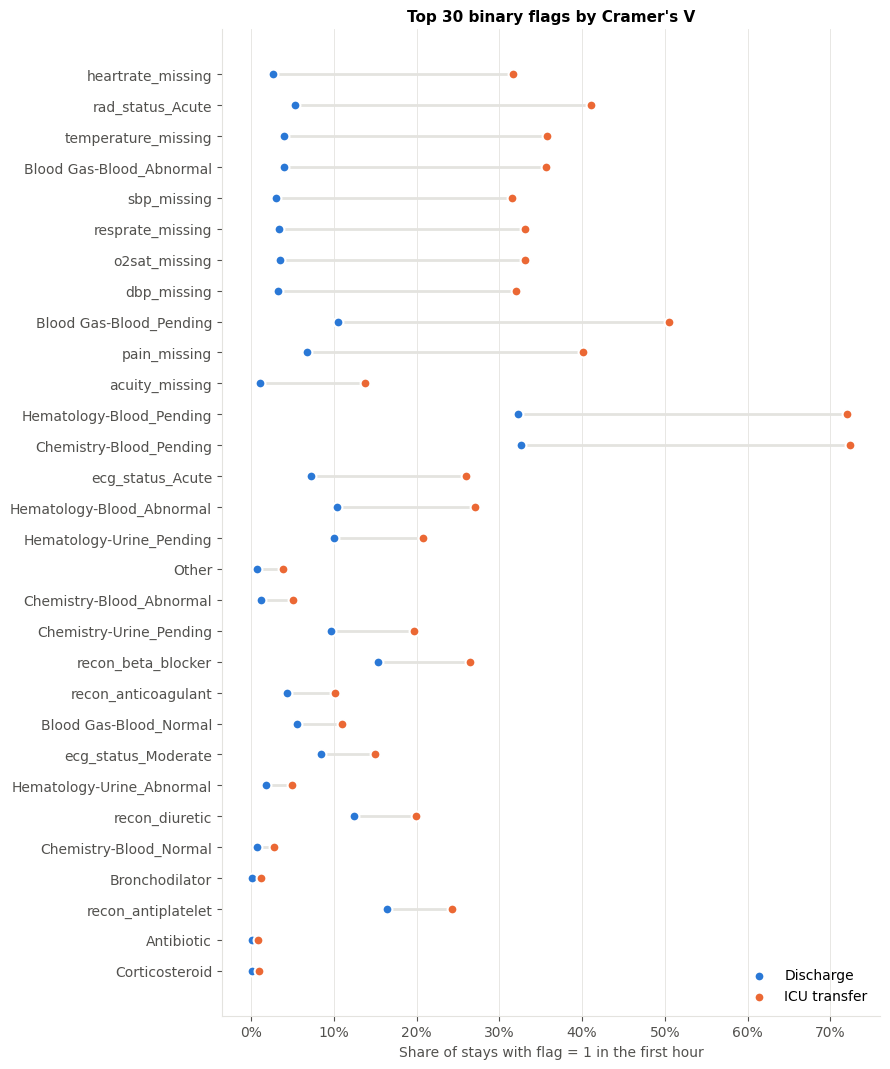

In [44]:
plot_prevalence_dumbbell(flag_results, top_n=30)

In [45]:
# Flags that are rare but highly concentrated in ICU stays have a low V but a high risk ratio
rare_but_strong = flag_results[(flag_results['prevalence_icu'] < 0.05) & (flag_results['risk_ratio'] > 3)]
rare_but_strong.sort_values('risk_ratio', ascending=False).head(20).style.format(flag_fmt)

,group,feature,prevalence_discharge,prevalence_icu,icu_rate_if_present,icu_rate_if_absent,risk_ratio,chi2,p,cramers_v,p_adj,effect
73,labs,Chemistry-Other Body Fluid_Normal,0.0%,0.0%,100.0%,8.5%,11.82,2,1.35e-01,0.007,1.70e-01,negligible
74,labs,Hematology-Other Body Fluid_Pending,0.0%,0.0%,100.0%,8.5%,11.82,2,1.35e-01,0.007,1.70e-01,negligible
47,labs,Hematology-Ascites_Pending,0.0%,0.2%,67.3%,8.4%,7.98,212,5.15e-48,0.033,1.05e-47,negligible
55,dispensed_meds,Anticonvulsant,0.0%,0.1%,66.7%,8.5%,7.89,98,5.02e-23,0.023,8.78e-23,negligible
50,labs,Chemistry-Ascites_Pending,0.0%,0.2%,62.8%,8.4%,7.43,157,5.08e-36,0.029,9.39e-36,negligible
31,dispensed_meds,Diuretic,0.0%,0.4%,62.3%,8.4%,7.39,420,2.72e-93,0.047,8.32e-93,negligible
69,micro,SPUTUM_Pending,0.0%,0.0%,55.6%,8.5%,6.57,20,7.51e-06,0.011,1.05e-05,negligible
56,micro,PERITONEAL FLUID_Pending,0.0%,0.1%,52.9%,8.5%,6.26,81,2.00e-19,0.021,3.37e-19,negligible
28,dispensed_meds,Antibiotic,0.1%,0.8%,52.3%,8.4%,6.23,632,1.97e-139,0.057,6.65e-139,negligible
38,dispensed_meds,Insulin/Glucose,0.0%,0.4%,51.7%,8.4%,6.13,284,1.04e-63,0.038,2.62e-63,negligible


_Observations:_

## 3. Administrative cohort fields (caution)

`insurance`, `language` and `marital_status` come from `hosp.admissions`, so they are **NULL for every ED discharge without a hospital admission**. Missingness by itself nearly encodes "was admitted", and every ICU transfer requires an admission. `discharge_location` is recorded **after** the outcome (e.g. DIED, HOSPICE), so it is a consequence of ICU care, not a predictor.

These fields are tested two ways:
1. **All stays, NULL as its own level:** shows the size of the leak.
2. **Admitted stays only (`hadm_id` not null):** a fairer comparison of ICU vs. ward patients where the field is actually populated.

None of these fields are model features; this section documents why.

In [46]:
ADMIN = ['insurance', 'language', 'marital_status', 'discharge_location']

admin = df_one[['ed_stay_id', TARGET]].merge(
    cohort_df[['ed_stay_id', 'hadm_id'] + ADMIN], on='ed_stay_id', how='left'
)
admin['admitted'] = admin['hadm_id'].notna()

print('Share NULL by outcome:')
display(admin.groupby(TARGET)[ADMIN].agg(lambda s: s.isna().mean()).rename(index=OUTCOME_NAMES).style.format('{:.1%}'))

admin_all = admin.copy()
admin_all[ADMIN] = admin_all[ADMIN].fillna('Missing')
admin_results = pd.concat([
    categorical_tests(admin_all, ADMIN).assign(subset='all stays (NULL = level)'),
    categorical_tests(admin[admin['admitted']], ADMIN).assign(subset='admitted only'),
], ignore_index=True)

admin_results[['subset', 'feature', 'levels', 'cramers_v', 'effect', 'p_adj', 'highest_icu_level', 'highest_icu_rate']].style.format({
    'cramers_v': '{:.3f}', 'p_adj': '{:.2e}', 'highest_icu_rate': '{:.1%}',
})

Share NULL by outcome:


,insurance,language,marital_status,discharge_location
label,,,,
Discharge,61.4%,60.1%,60.9%,77.0%
ICU transfer,3.1%,0.6%,13.3%,1.7%


,subset,feature,levels,cramers_v,effect,p_adj,highest_icu_level,highest_icu_rate
0,all stays (NULL = level),discharge_location,13,0.575,large,0.00e+00,DIED,86.9%
1,all stays (NULL = level),insurance,6,0.342,medium,0.00e+00,Medicare,23.3%
2,all stays (NULL = level),language,26,0.334,medium,0.00e+00,Khmer,40.0%
3,all stays (NULL = level),marital_status,5,0.273,small,0.00e+00,WIDOWED,20.9%
4,admitted only,discharge_location,12,0.394,medium,0.00e+00,DIED,86.9%
5,admitted only,insurance,5,0.108,small,2.47e-216,Medicare,23.3%
6,admitted only,marital_status,4,0.065,negligible,2.26e-76,WIDOWED,20.9%
7,admitted only,language,25,0.027,negligible,8.12e-06,Khmer,40.0%


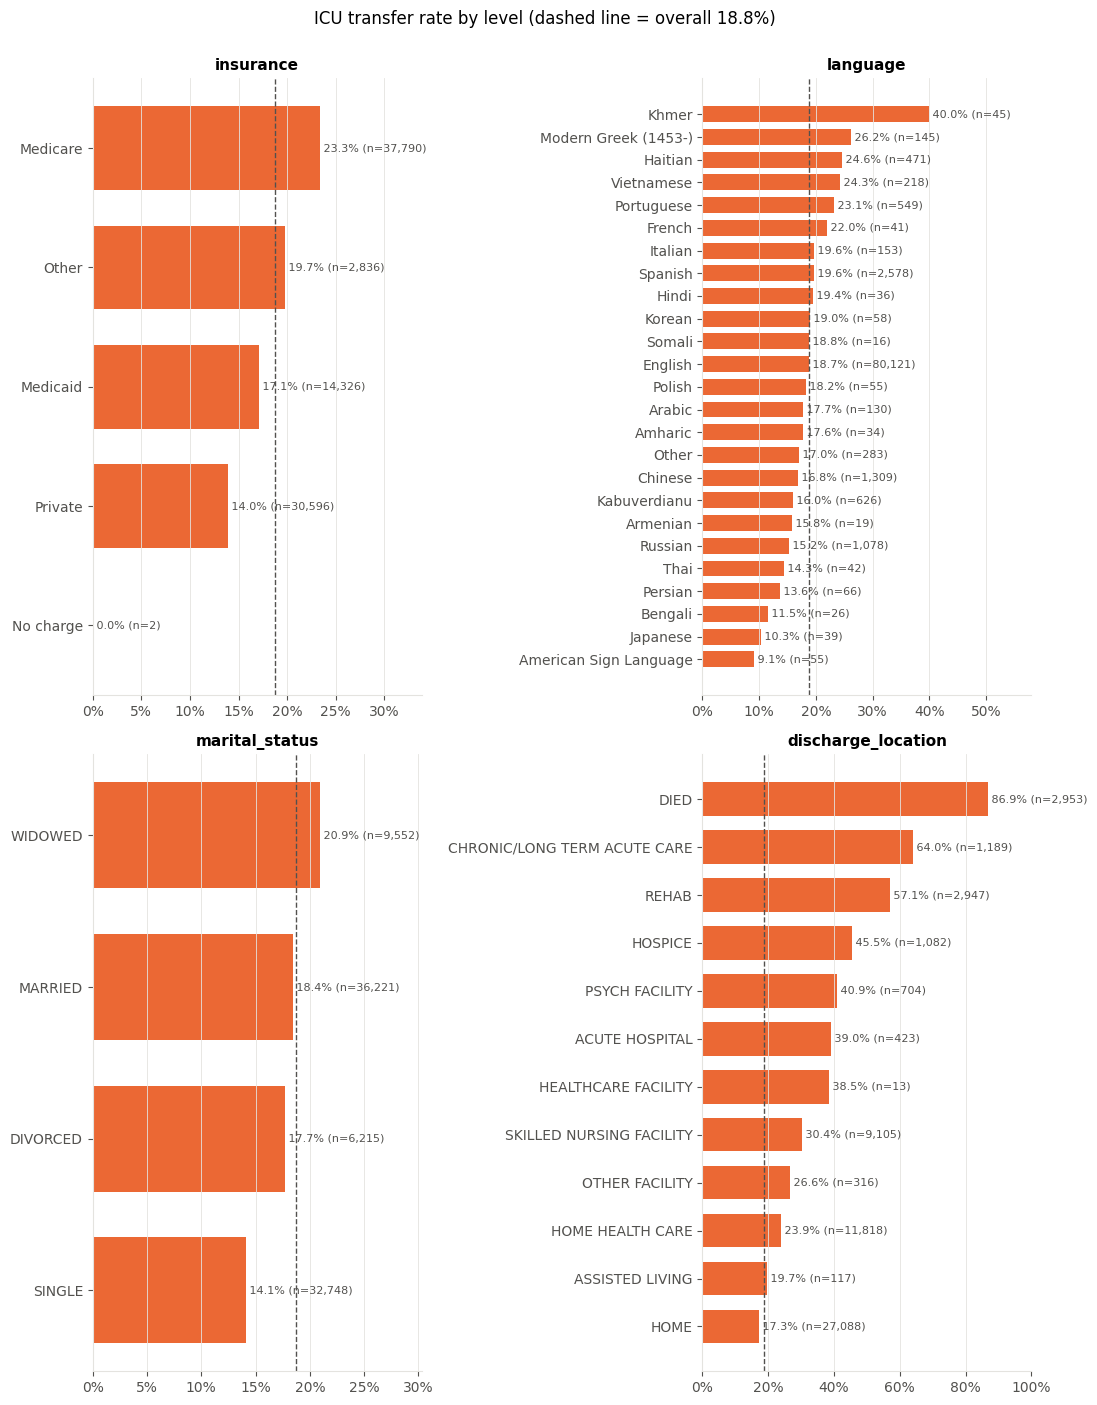

In [47]:
plot_icu_rate_grid(admin[admin['admitted']], ADMIN, ncols=2)

_Observations:_ (compare V between the two subsets; a large drop means most of the signal was the NULL pattern)

## 4. Model-based ranking (multivariate first pass)

Univariate tests look at one feature at a time. These two methods give a first look at how features rank once the others are considered. This is a screening step, not the final model.

- **Mutual information:** model-free, captures non-linear and non-monotonic relationships (e.g. U-shaped heart rate risk) that correlations miss. Univariate, but no shape assumptions.
- **Random forest permutation importance:** drop in held-out PR-AUC when a feature is shuffled. This is multivariate, so it shows which features add information beyond the others. Correlated features (sbp/dbp/map, lab Normal/Abnormal pairs) split credit, so a low score doesn't mean a feature is uninformative on its own. Permutation importance was chosen over impurity importance, which is biased toward continuous, high-cardinality features.

Both run on a stratified 50k subsample of `df_one` for speed. Imputed values are kept as-is here because that is what the models see.

In [48]:
drop_cols = {'ed_stay_id', 'subject_id', TARGET, 'chiefcomplaint', 'gender_label', 'arrival'}
model_df = pd.get_dummies(
    df_one.drop(columns=[c for c in drop_cols if c in df_one.columns]),
    columns=['race', 'cc_category'], prefix=['race', 'cc'], dtype=int,
)
model_df = model_df.select_dtypes('number')
model_df = model_df.fillna(model_df.median())

X_sample, _, y_sample, _ = train_test_split(
    model_df, df_one[TARGET], train_size=min(50_000, len(df_one) // 2), stratify=df_one[TARGET], random_state=RANDOM_STATE
)
discrete_mask = X_sample.nunique().le(2).values
print(X_sample.shape, f'{discrete_mask.sum()} discrete features')

KeyError: "['race'] not in index"

In [49]:
mi = mutual_info_classif(X_sample, y_sample, discrete_features=discrete_mask, random_state=RANDOM_STATE)
mi = pd.Series(mi, index=X_sample.columns, name='mutual_info')
plot_ranked(mi, 'Top 25 features by mutual information', 'Mutual information (nats)')

NameError: name 'X_sample' is not defined

In [ ]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X_sample, y_sample, test_size=0.3, stratify=y_sample, random_state=RANDOM_STATE
)
rf = RandomForestClassifier(
    n_estimators=200, max_depth=10, min_samples_leaf=20, class_weight='balanced',
    n_jobs=-1, random_state=RANDOM_STATE,
)
rf.fit(X_tr, y_tr)
print(f'Held-out PR-AUC: {average_precision_score(y_te, rf.predict_proba(X_te)[:, 1]):.3f} (baseline {y_te.mean():.3f})')

perm = permutation_importance(
    rf, X_te, y_te, scoring='average_precision', n_repeats=3, random_state=RANDOM_STATE, n_jobs=1
)
perm_imp = pd.Series(perm.importances_mean, index=X_te.columns, name='perm_importance')
plot_ranked(perm_imp, 'Top 25 features by RF permutation importance', 'Mean drop in PR-AUC', color=OUTCOME_COLORS[1])

## 5. Combined summary

One row per feature with its univariate effect size and both model-based scores, ranked within each column. Dummy columns (`race_*`, `cc_*`, `arrival_*`) are rolled up to their parent feature using the max score. Features that rank high on all three are the strongest candidates to discuss in the paper. Disagreements are worth a sentence too: high MI with low permutation importance usually means the information is redundant with another feature.

In [50]:
def parent_feature(col):
    for prefix, parent in (('race_', 'race'), ('cc_', 'cc_category'), ('arrival_', 'arrival')):
        if col.startswith(prefix):
            return parent
    return col


univariate = pd.concat([
    cont_results[['feature', 'rank_biserial_r', 'mwu_p_adj', 'effect']]
        .rename(columns={'rank_biserial_r': 'effect_size', 'mwu_p_adj': 'p_adj'})
        .assign(kind='continuous/ordinal', metric='rank-biserial r'),
    cat_results.loc[~cat_results['feature'].isin(ORDINAL), ['feature', 'cramers_v', 'p_adj', 'effect']]
        .rename(columns={'cramers_v': 'effect_size'})
        .assign(kind='categorical', metric="Cramer's V"),
    flag_results[['feature', 'group', 'cramers_v', 'p_adj', 'effect', 'risk_ratio']]
        .rename(columns={'cramers_v': 'effect_size'})
        .assign(kind='binary flag', metric="Cramer's V"),
], ignore_index=True)
univariate['feature'] = univariate['feature'].replace({'gender_label': 'gender'})

model_scores = pd.concat([mi, perm_imp], axis=1)
model_scores = model_scores.groupby(model_scores.index.map(parent_feature)).max()

summary = univariate.merge(model_scores, left_on='feature', right_index=True, how='left')
summary['abs_effect'] = summary['effect_size'].abs()
for col in ('abs_effect', 'mutual_info', 'perm_importance'):
    summary[f'rank_{col}'] = summary[col].rank(ascending=False, method='min')
summary['mean_rank'] = summary[['rank_abs_effect', 'rank_mutual_info', 'rank_perm_importance']].mean(axis=1)
summary = summary.sort_values('mean_rank').reset_index(drop=True)

summary.head(30).style.format({
    'effect_size': '{:.3f}', 'abs_effect': '{:.3f}', 'p_adj': '{:.2e}', 'risk_ratio': '{:.2f}',
    'mutual_info': '{:.4f}', 'perm_importance': '{:.4f}', 'mean_rank': '{:.1f}',
    'rank_abs_effect': '{:.0f}', 'rank_mutual_info': '{:.0f}', 'rank_perm_importance': '{:.0f}',
})

NameError: name 'cat_results' is not defined

In [51]:
# How many features clear each effect-size bar, by type
pd.crosstab(summary['kind'], summary['effect']).reindex(columns=['negligible', 'small', 'medium', 'large'], fill_value=0)

NameError: name 'summary' is not defined

_Key findings for the paper:_